=== DFT de N=4 ===
x[n] = [1 2 0 1]
X[k] = [ 4.+0.j  1.-1.j -2.+0.j  1.+1.j]

=== DFT de N=8 ===
x8[n] = [ 2.5     2.4142  1.5     2.4142  2.5    -0.4142 -2.5    -0.4142]
X8[k] = [ 8.+0.j -0.-8.j  6.-0.j  0.+0.j  0.+0.j  0.+0.j  6.+0.j -0.+8.j]


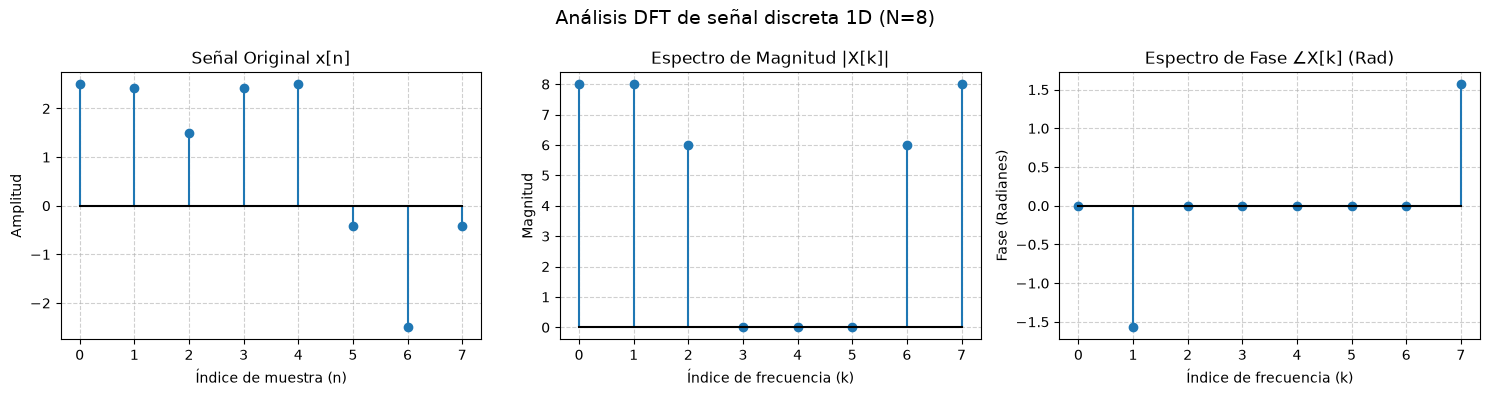

In [1]:
import numpy as np
import matplotlib.pyplot as plt

# VERIFICACION DEL CALCULO ANALITICO (N=4)
x4 = np.array([1, 2, 0, 1])
X4 = np.fft.fft(x4)
print("=== DFT de N=4 ===")
print("x[n] =", x4)
print("X[k] =", np.round(X4, 4))

# SENAL DISCRETA DE N=8 CON DOS SINUSOIDES
N = 8
n = np.arange(N)
# Frecuencias digitales: k1=1 ciclo/N, k2=2 ciclos/N
x8 = 2 * np.sin(2 * np.pi * 1 * n / N) + 1.5 * np.cos(2 * np.pi * 2 * n / N) + 1.0 # Agregamos un offset DC de 1.0

# 3. CALCULO DE LA DFT (N=8)
X8 = np.fft.fft(x8)

# Visualizacion resultados analitico
print("\n=== DFT de N=8 ===")
print("x8[n] =", np.round(x8, 4))
print("X8[k] =", np.round(X8, 4))

mag_X8 = np.abs(X8)
fase_X8 = np.angle(X8)

# Tolerancia para limpiar ruido numerico en la fase
fase_X8[mag_X8 < 1e-6] = 0

# 4. VISUALIZACION
fig, axes = plt.subplots(1, 3, figsize=(15, 4))
fig.suptitle('Análisis DFT de señal discreta 1D (N=8)', fontsize=14)

# Señal en el tiempo discreto
axes[0].stem(n, x8, basefmt="black")
axes[0].set_title('Señal Original x[n]')
axes[0].set_xlabel('Índice de muestra (n)')
axes[0].set_ylabel('Amplitud')
axes[0].grid(True, linestyle='--', alpha=0.6)

# Magnitud 
axes[1].stem(n, mag_X8, basefmt="black")
axes[1].set_title('Espectro de Magnitud |X[k]|')
axes[1].set_xlabel('Índice de frecuencia (k)')
axes[1].set_ylabel('Magnitud')
axes[1].grid(True, linestyle='--', alpha=0.6)

# Fase 
axes[2].stem(n, fase_X8, basefmt="black")
axes[2].set_title('Espectro de Fase ∠X[k] (Rad)')
axes[2].set_xlabel('Índice de frecuencia (k)')
axes[2].set_ylabel('Fase (Radianes)')
axes[2].grid(True, linestyle='--', alpha=0.6)

plt.tight_layout()
plt.show()

Error absoluto maximo (reconstruccion completa): 2.22e-16


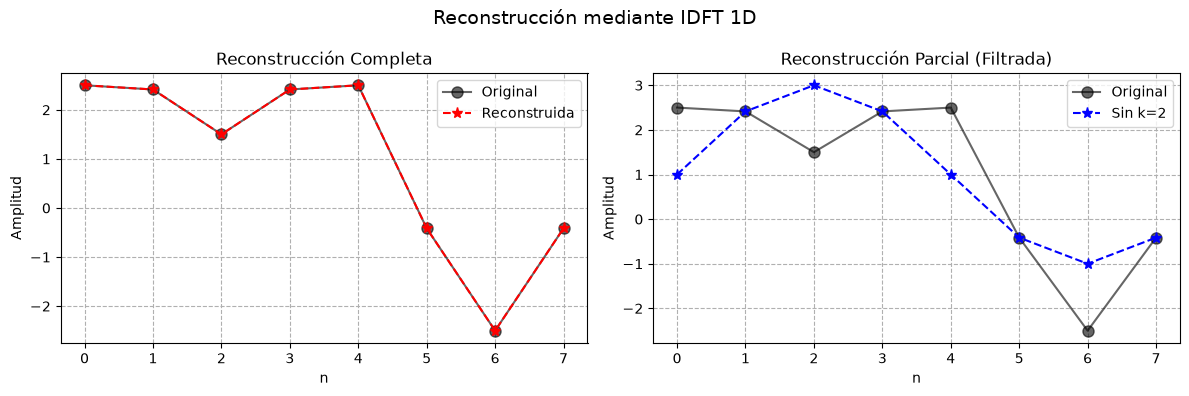

In [2]:
import numpy as np
import matplotlib.pyplot as plt

# 1. RECONSTRUCCION COMPLETA (Usando X8 de la act. 5.1)
N = 8
n = np.arange(N)
x8 = 2 * np.sin(2 * np.pi * 1 * n / N) + 1.5 * np.cos(2 * np.pi * 2 * n / N) + 1.0
X8 = np.fft.fft(x8)

x8_rec = np.fft.ifft(X8)
error_max = np.max(np.abs(x8 - x8_rec.real))
print(f"Error absoluto maximo (reconstruccion completa): {error_max:.2e}")

# 2. RECONSTRUCCION PARCIAL (Filtrado)
X8_mod = X8.copy()
# Eliminamos la frecuencia k=2 y su conjugado k=6 (N-k = 8-2 = 6)
X8_mod[2] = 0
X8_mod[6] = 0

x8_rec_mod = np.fft.ifft(X8_mod)

# 3. VISUALIZACION
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
fig.suptitle('Reconstrucción mediante IDFT 1D', fontsize=14)

# Reconstruccion Completa
axes[0].plot(n, x8, 'ko-', label='Original', markersize=8, alpha=0.6)
axes[0].plot(n, x8_rec.real, 'r*--', label='Reconstruida', markersize=8)
axes[0].set_title('Reconstrucción Completa')
axes[0].set_xlabel('n')
axes[0].set_ylabel('Amplitud')
axes[0].grid(True, linestyle='--')
axes[0].legend()

# Reconstruccion Parcial
axes[1].plot(n, x8, 'ko-', label='Original', markersize=8, alpha=0.6)
axes[1].plot(n, x8_rec_mod.real, 'b*--', label='Sin k=2', markersize=8)
axes[1].set_title('Reconstrucción Parcial (Filtrada)')
axes[1].set_xlabel('n')
axes[1].set_ylabel('Amplitud')
axes[1].grid(True, linestyle='--')
axes[1].legend()

plt.tight_layout()
plt.show()

In [4]:
import os
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
import ipywidgets as widgets
from IPython.display import display

# =============================================================================
# 1. VERIFICACION ANALITICA VS. NUMERICA (Matriz 2x2)
# =============================================================================
def verificacion_analitica():
    f = np.array([[1, 2],
                  [3, 4]], dtype=np.float64)

    # FFT 2D numerica
    F_num = np.fft.fft2(f)

    # Resultado analitico derivado
    F_analitico = np.array([[10.0 + 0.0j, -2.0 + 0.0j],
                            [-4.0 + 0.0j,  0.0 + 0.0j]], dtype=np.complex128)

    error_max = np.max(np.abs(F_num - F_analitico))

    print("=" * 60)
    print("COMPROBACION ANALITICA DE LA DFT 2D (Ejercicio 5.3)")
    print("=" * 60)
    print("Matriz f[x,y]:\n", f)
    print("\nDFT 2D Analitica F[u,v]:\n", F_analitico)
    print("\nDFT 2D Numerica (np.fft.fft2):\n", F_num)
    print(f"\nError Absoluto Maximo: {error_max:.2e}")
    print("Coincidencia:", "EXACTA" if error_max < 1e-12 else "DIVERGENTE")
    print("=" * 60 + "\n")

verificacion_analitica()

# =============================================================================
# 2. CARGA Y ADAPTACION DE LAS TRES IMAGENES
# =============================================================================
RUTA_FIGURA_GEOMETRICA = '01_rectangulo.png'
RUTA_PAISAJE           = '02_paisaje.png'
RUTA_ESCENA_URBANA     = '03_escena_urbana.png'

N = 255  # Dimension requerida por la guia (255x255 pixeles)

def cargar_imagen_usuario(ruta_archivo, tipo_sintetico_respaldo="rectangulo"):
    """
    Lee la imagen desde el disco, la convierte a escala de grises de 8 bits (0-255)
    y ajusta sus dimensiones a 255x255 pixeles.
    Si el archivo no se encuentra, genera una matriz sintetica de respaldo.
    """
    if os.path.exists(ruta_archivo):
        img = Image.open(ruta_archivo).convert('L').resize((N, N))
        print(f"[OK] Imagen cargada correctamente: '{ruta_archivo}'")
        return np.array(img, dtype=np.float32)
    else:
        print(f"[AVISO] No se encontro el archivo '{ruta_archivo}'. Usando imagen sintetica de respaldo...")
        if tipo_sintetico_respaldo == "rectangulo":
            syn = np.zeros((N, N), dtype=np.float32)
            syn[80:175, 50:205] = 255.0
            return syn
        elif tipo_sintetico_respaldo == "paisaje":
            x, y = np.meshgrid(np.linspace(-3, 3, N), np.linspace(-3, 3, N))
            return np.clip(128 + 60 * np.sin(x) * np.cos(y) + 20 * np.sin(10 * x), 0, 255).astype(np.float32)
        else:
            syn = np.zeros((N, N), dtype=np.float32) + 40
            for i in range(15, N, 25): syn[:, i:i+5] += 120
            for j in range(20, N, 30): syn[j:j+5, :] += 70
            return np.clip(syn, 0, 255).astype(np.float32)

# Cargar las tres imagenes en un diccionario
imagenes = {
    '1. Figura Geometrica': cargar_imagen_usuario(RUTA_FIGURA_GEOMETRICA, "rectangulo"),
    '2. Paisaje': cargar_imagen_usuario(RUTA_PAISAJE, "paisaje"),
    '3. Escena Urbana': cargar_imagen_usuario(RUTA_ESCENA_URBANA, "urbana")
}

# =============================================================================
# 3. INTERFAZ INTERACTIVA POR PESTANAS (ipywidgets)
# =============================================================================
out1, out2, out3 = widgets.Output(), widgets.Output(), widgets.Output()
tab = widgets.Tab(children=[out1, out2, out3])
tab.set_title(0, 'Figura Geometrica')
tab.set_title(1, 'Paisaje')
tab.set_title(2, 'Escena Urbana')

def renderizar_experiencia_5_3(output_widget, img_matriz, titulo_pestana, archivo):
    with output_widget:
        output_widget.clear_output()

        # 1. DFT 2D y centrado de frecuencias
        F = np.fft.fft2(img_matriz)
        F_shifted = np.fft.fftshift(F)

        # 2. Espectro de magnitud logaritmica log(1 + |F|) y espectro de fase
        espectro_log = np.log(1 + np.abs(F_shifted))
        fase = np.angle(F_shifted)

        # 3. Reconstruccion con IDFT 2D
        img_reconstruida = np.real(np.fft.ifft2(np.fft.ifftshift(F_shifted)))
        error_reconstruccion = np.max(np.abs(img_matriz - img_reconstruida))

        # 4. Despliegue de cuadricula 2x2
        fig, axes = plt.subplots(2, 2, figsize=(9, 9))
        fig.suptitle(f'Ejercicio 5.3: DFT 2D - {titulo_pestana}\nDimension: {N}x{N} pixeles | Escala de Grises (8 bits)',
                     fontsize=12, fontweight='bold')

        # Imagen Original
        im0 = axes[0, 0].imshow(img_matriz, cmap='gray', vmin=0, vmax=255)
        axes[0, 0].set_title('1. Imagen Original $f[x,y]$')
        axes[0, 0].axis('off')
        plt.colorbar(im0, ax=axes[0, 0], fraction=0.046, pad=0.04)

        # Espectro de Magnitud Logaritmica
        im1 = axes[0, 1].imshow(espectro_log, cmap='magma')
        axes[0, 1].set_title(r'2. Espectro Magnitud $\log(1 + |F[u,v]|)$')
        axes[0, 1].set_xlabel('Frecuencia $u$')
        axes[0, 1].set_ylabel('Frecuencia $v$')
        plt.colorbar(im1, ax=axes[0, 1], fraction=0.046, pad=0.04)

        # Espectro de Fase
        im2 = axes[1, 0].imshow(fase, cmap='twilight', vmin=-np.pi, vmax=np.pi)
        axes[1, 0].set_title(r'3. Espectro de Fase $\varphi(u,v) = \text{atan2}(\text{Im}, \text{Re})$')
        axes[1, 0].axis('off')
        plt.colorbar(im2, ax=axes[1, 0], fraction=0.046, pad=0.04)

        # Reconstruccion IDFT 2D
        im3 = axes[1, 1].imshow(img_reconstruida, cmap='gray', vmin=0, vmax=255)
        axes[1, 1].set_title(f'4. Reconstruccion IDFT 2D\n(Error Max: {error_reconstruccion:.2e})')
        axes[1, 1].axis('off')
        plt.colorbar(im3, ax=axes[1, 1], fraction=0.046, pad=0.04)

        plt.tight_layout()
        plt.savefig(archivo, dpi=300)
        plt.show()

# Renderizar en las 3 pestanas de la interfaz
display(tab)
renderizar_experiencia_5_3(out1, imagenes['1. Figura Geometrica'], 'Figura Geometrica', '5_3_dft2d_figura.png')
renderizar_experiencia_5_3(out2, imagenes['2. Paisaje'], 'Paisaje', '5_3_dft2d_paisaje.png')
renderizar_experiencia_5_3(out3, imagenes['3. Escena Urbana'], 'Escena Urbana', '5_3_dft2d_urbana.png')

COMPROBACION ANALITICA DE LA DFT 2D (Ejercicio 5.3)
Matriz f[x,y]:
 [[1. 2.]
 [3. 4.]]

DFT 2D Analitica F[u,v]:
 [[10.+0.j -2.+0.j]
 [-4.+0.j  0.+0.j]]

DFT 2D Numerica (np.fft.fft2):
 [[10.+0.j -2.+0.j]
 [-4.+0.j  0.+0.j]]

Error Absoluto Maximo: 0.00e+00
Coincidencia: EXACTA

[AVISO] No se encontro el archivo '01_rectangulo.png'. Usando imagen sintetica de respaldo...
[AVISO] No se encontro el archivo '02_paisaje.png'. Usando imagen sintetica de respaldo...
[AVISO] No se encontro el archivo '03_escena_urbana.png'. Usando imagen sintetica de respaldo...


In [6]:
import numpy as np
import matplotlib
matplotlib.use("Agg")
import matplotlib.pyplot as plt

N = 255
c = N // 2   # centro (127)

def rectangulo(W, H, theta_deg=0.0):
    """Rectangulo blanco de ancho W y alto H centrado, rotado theta grados."""
    y, x = np.mgrid[0:N, 0:N]
    xc, yc = x - c, y - c
    t = np.deg2rad(theta_deg)
    xr =  xc * np.cos(t) + yc * np.sin(t)
    yr = -xc * np.sin(t) + yc * np.cos(t)
    img = (np.abs(xr) <= W / 2) & (np.abs(yr) <= H / 2)
    return 255.0 * img

def espectro(img):
    return np.log1p(np.abs(np.fft.fftshift(np.fft.fft2(img))))

casos = [
    ("Base\nW=65, H=105",           rectangulo(65, 105)),
    ("Doble ancho\nW=130, H=105",   rectangulo(130, 105)),
    ("Doble alto\nW=65, H=210",     rectangulo(65, 210)),
    ("Rotado 30 grados\nW=65, H=105", rectangulo(65, 105, 30)),
]

fig, axes = plt.subplots(2, 4, figsize=(14, 8))
fig.suptitle("Efecto del ancho, la altura y la orientacion en el espectro", fontsize=13, fontweight="bold")
for j, (titulo, img) in enumerate(casos):
    axes[0, j].imshow(img, cmap="gray", vmin=0, vmax=255)
    axes[0, j].set_title(titulo)
    axes[0, j].axis("off")
    axes[1, j].imshow(espectro(img), cmap="magma")
    axes[1, j].set_title(r"$\log(1+|F|)$")
    axes[1, j].axis("off")
plt.tight_layout(rect=[0, 0, 1, 0.96], h_pad=2.5)
plt.savefig("5_3_rect_variaciones.png", dpi=300)
plt.show()

C:\Users\julio\AppData\Local\Temp\ipykernel_10728\168584438.py:40: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()


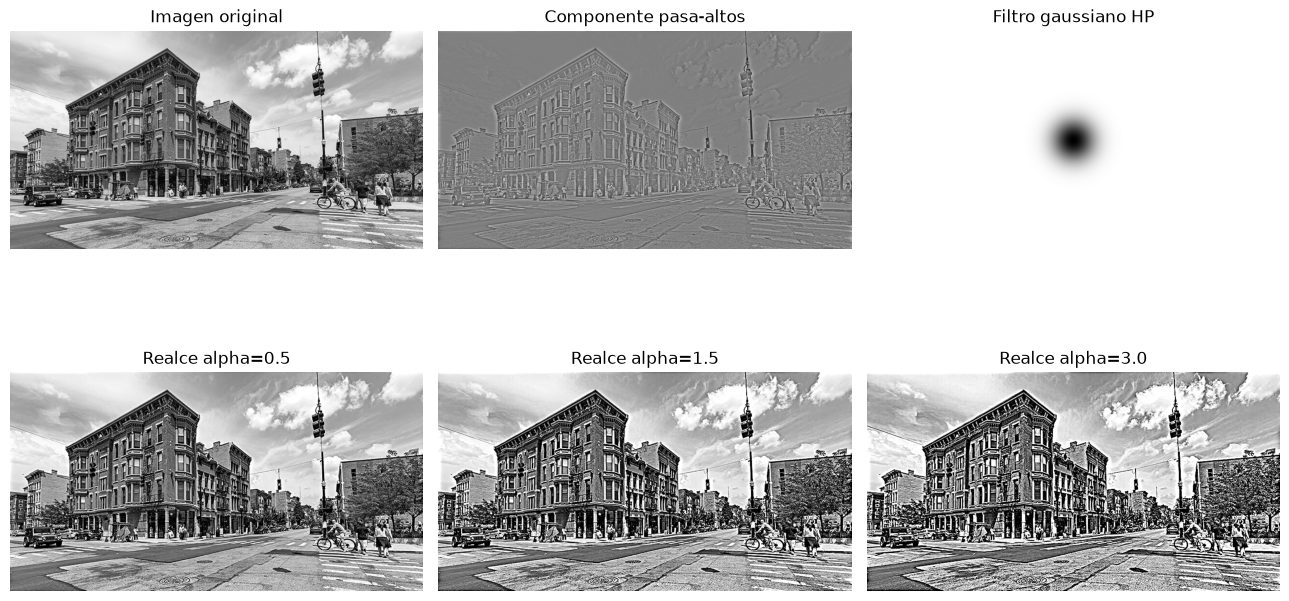

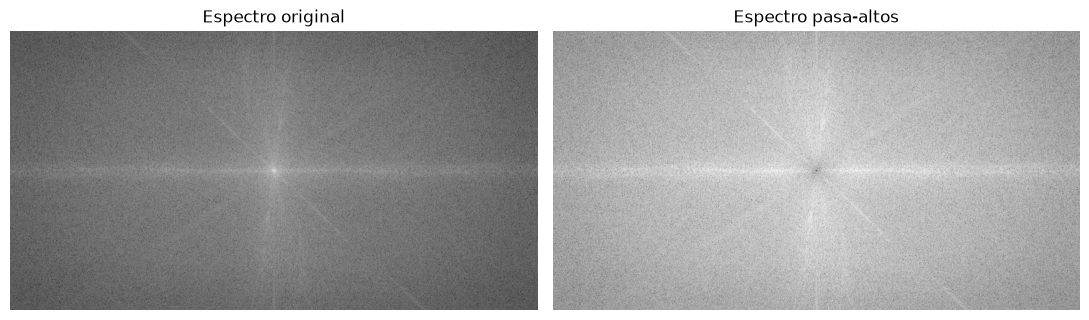

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Cargar imagen en escala de grises
img = np.asarray(
    Image.open("escena_urbana.jpg").convert("L"),
    dtype=np.float64
)

M, N = img.shape

# 2. Transformada de Fourier
F = np.fft.fftshift(np.fft.fft2(img))

# 3. Distancia al centro del espectro
u = np.arange(M) - M // 2
v = np.arange(N) - N // 2
V, U = np.meshgrid(v, u)
D2 = U**2 + V**2

# 4. Filtro pasa-altos gaussiano
D0 = 30

H_LP = np.exp(-D2 / (2 * D0**2))
H_HP = 1 - H_LP

# 5. Aplicar filtro en frecuencia
F_HP = F * H_HP

# 6. Transformada inversa
f_HP = np.real(
    np.fft.ifft2(np.fft.ifftshift(F_HP))
)

# 7. Realce de imagen
alphas = [0.5, 1.5, 3.0]

realzadas = [
    np.clip(img + a * f_HP, 0, 255)
    for a in alphas
]

# 8. Espectros logaritmicos
espectro_original = np.log1p(np.abs(F))
espectro_HP = np.log1p(np.abs(F_HP))

# 9. Comparacion de imagenes
fig, ax = plt.subplots(2, 3, figsize=(13, 8))

ax[0, 0].imshow(img, cmap="gray",
                vmin=0, vmax=255)
ax[0, 0].set_title("Imagen original")

ax[0, 1].imshow(f_HP, cmap="gray")
ax[0, 1].set_title("Componente pasa-altos")

ax[0, 2].imshow(H_HP, cmap="gray",
                vmin=0, vmax=1)
ax[0, 2].set_title("Filtro gaussiano HP")

for i, a in enumerate(alphas):
    ax[1, i].imshow(realzadas[i],
                    cmap="gray",
                    vmin=0, vmax=255)
    ax[1, i].set_title(f"Realce alpha={a}")

for a in ax.flat:
    a.axis("off")

plt.tight_layout()
plt.savefig("comparacion_realce.png", dpi=300)
plt.show()

# 10. Comparacion de espectros
fig, ax = plt.subplots(1, 2, figsize=(11, 5))

ax[0].imshow(espectro_original, cmap="gray")
ax[0].set_title("Espectro original")

ax[1].imshow(espectro_HP, cmap="gray")
ax[1].set_title("Espectro pasa-altos")

for a in ax:
    a.axis("off")

plt.tight_layout()
plt.savefig("comparacion_espectros.png", dpi=300)
plt.show()

In [8]:
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

# 1. Preparacion de la imagen (255x255)
img = Image.open('03_escena_urbana.png').convert('L')
img = img.resize((255, 255))
f = np.array(img, dtype=float)

# 2. Anadir interferencia sinusoidal (Ruido Periodico)
A = 50       # Amplitud
u_r = 0      # Frecuencia espacial en el eje x
v_r = 18     # Frecuencia espacial en el eje y

# Construccion de la malla espacial
x = np.arange(255)
y = np.arange(255)
X, Y = np.meshgrid(x, y)

# Ecuacion del ruido
ruido = A * np.sin(2 * np.pi * (u_r * X / 255 + v_r * Y / 255))
f_ruido = f + ruido

# 3. Transformada de Fourier 2D
F = np.fft.fft2(f_ruido)
F_shift = np.fft.fftshift(F)
F_mag = np.log1p(np.abs(F_shift)) # log(1 + |F|) para visualizacion

# 4. Construir filtro notch ideal simetrico
H = np.ones((255, 255))
D0 = 5 # Ancho de rechazo (radio del agujero)
cx, cy = 255 // 2, 255 // 2

# Ubicacion de los dos picos conjugados
pico1 = (cy + v_r, cx + u_r)
pico2 = (cy - v_r, cx - u_r)

# Rechazo localizado creando agujeros (0s) en la mascara
for i in range(255):
    for j in range(255):
        d1 = np.sqrt((i - pico1[0])**2 + (j - pico1[1])**2)
        d2 = np.sqrt((i - pico2[0])**2 + (j - pico2[1])**2)
        if d1 <= D0 or d2 <= D0:
            H[i, j] = 0

# 5. Filtrado y Reconstruccion
G_shift = H * F_shift
G_mag = np.log1p(np.abs(G_shift))

# Transformada Inversa
g_reconstruida = np.real(np.fft.ifft2(np.fft.ifftshift(G_shift)))

# 6. Visualizacion de los resultados
fig, axes = plt.subplots(2, 3, figsize=(13, 8))

axes[0, 0].imshow(f, cmap='gray')
axes[0, 0].set_title('Imagen Original')
axes[0, 1].imshow(f_ruido, cmap='gray')
axes[0, 1].set_title('Imagen con Ruido Periodico')
axes[0, 2].imshow(F_mag, cmap='gray')
axes[0, 2].set_title('Espectro (Magnitud)')

axes[1, 0].imshow(H, cmap='gray')
axes[1, 0].set_title('Filtro Notch')
axes[1, 1].imshow(G_mag, cmap='gray')
axes[1, 1].set_title('Espectro Filtrado')
axes[1, 2].imshow(g_reconstruida, cmap='gray')
axes[1, 2].set_title('Imagen Recuperada')

for ax in axes.flat:
    ax.axis('off')

plt.tight_layout()
plt.savefig("5_6_resultados_notch.png", dpi=300)
plt.show()

C:\Users\julio\AppData\Local\Temp\ipykernel_10728\4023290061.py:75: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown
  plt.show()
